In [ ]:
stall lib ansd upload csv file

In [1]:
!pip -q install pandas numpy scikit-learn sqlalchemy pymysql
from google.colab import files

uploaded = files.upload()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00


Saving transaction.csv to transaction.csv


load the data

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("transaction.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (1000, 9)

Columns:
['transaction_id', 'customer_id', 'payment_method', 'gateway_name', 'amount', 'status', 'error_code', 'created_at', 'updated_at']


,transaction_id,customer_id,payment_method,gateway_name,amount,status,error_code,created_at,updated_at
0,TXN_000001,CUST_0328,UPI,Razorpay,18564.61,FAILED,ERR_INSUFFICIENT_FUNDS,01-02-2026 07:08,01-02-2026 07:08
1,TXN_000002,CUST_0048,Credit Card,Razorpay,12683.35,FAILED,ERR_INVALID_OTP,04-01-2026 17:12,04-01-2026 17:12
2,TXN_000003,CUST_0415,UPI,Razorpay,17483.67,SUCCESS,NaN,13-02-2026 08:09,13-02-2026 08:09
3,TXN_000004,CUST_0195,UPI,Cashfree,21202.61,SUCCESS,NaN,19-03-2026 08:51,19-03-2026 08:51
4,TXN_000005,CUST_0499,NetBanking,Razorpay,13845.81,FAILED,ERR_GATEWAY_TIMEOUT,22-03-2026 19:56,22-03-2026 19:56


check and clean the data

In [4]:
# Check missing values
print(df.isnull().sum())

# Check transaction status categories
print(df["status"].value_counts(dropna=False))

# Convert columns to correct data types
df["amount"] = pd.to_numeric(df["amount"], errors="coerce")
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")

# Remove rows missing essential information
df = df.dropna(
    subset=[
        "transaction_id",
        "customer_id",
        "payment_method",
        "gateway_name",
        "amount",
        "status",
        "created_at"
    ]
)

# Standardize status values
df["status"] = df["status"].astype(str).str.strip().str.upper()

print("\nCleaned dataset shape:", df.shape)
print(df["status"].value_counts())

transaction_id      0
customer_id         0
payment_method      0
gateway_name        0
amount              0
status              0
error_code        695
created_at          0
updated_at          0
dtype: int64
status
SUCCESS    695
FAILED     194
PENDING    111
Name: count, dtype: int64

Cleaned dataset shape: (413, 9)
status
SUCCESS    293
FAILED      81
PENDING     39
Name: count, dtype: int64


Create the target variable

In [5]:
# Keep only transactions with a known final outcome
df = df[df["status"].isin(["SUCCESS", "FAILED"])].copy()

# Create the target variable
df["payment_failed"] = (df["status"] == "FAILED").astype(int)

print(df[["transaction_id", "status", "payment_failed"]].head(10))

print("\nTarget distribution:")
print(df["payment_failed"].value_counts())

   transaction_id   status  payment_failed
0      TXN_000001   FAILED               1
1      TXN_000002   FAILED               1
8      TXN_000009  SUCCESS               0
9      TXN_000010   FAILED               1
11     TXN_000012  SUCCESS               0
16     TXN_000017  SUCCESS               0
17     TXN_000018  SUCCESS               0
18     TXN_000019  SUCCESS               0
21     TXN_000022  SUCCESS               0
24     TXN_000025  SUCCESS               0

Target distribution:
payment_failed
0    293
1     81
Name: count, dtype: int64


Create date and time features

In [6]:
# Sort transactions chronologically
df = df.sort_values("created_at").reset_index(drop=True)

# Extract time-based features
df["hour"] = df["created_at"].dt.hour
df["day_of_week"] = df["created_at"].dt.dayofweek

# Monday = 0, Sunday = 6
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Define peak hours as 6 PM to 10 PM
df["is_peak_hour"] = df["hour"].between(18, 21).astype(int)

print(
    df[
        [
            "created_at",
            "hour",
            "day_of_week",
            "is_weekend",
            "is_peak_hour"
        ]
    ].head()
)

           created_at  hour  day_of_week  is_weekend  is_peak_hour
0 2026-01-01 09:18:00     9            3           0             0
1 2026-01-01 14:17:00    14            3           0             0
2 2026-01-01 15:47:00    15            3           0             0
3 2026-01-01 16:49:00    16            3           0             0
4 2026-01-01 20:14:00    20            3           0             1


Calculate historical failure rates

In [7]:
def add_previous_failure_rate(data, group_column, new_column):
    data[new_column] = (
        data.groupby(group_column)["payment_failed"]
        .transform(lambda s: s.shift(1).expanding().mean())
    )

    # No historical transactions available yet
    data[new_column] = data[new_column].fillna(0.0)

    return data


df = add_previous_failure_rate(
    df, "customer_id", "customer_previous_failure_rate"
)

df = add_previous_failure_rate(
    df, "gateway_name", "gateway_failure_rate"
)

df = add_previous_failure_rate(
    df, "payment_method", "payment_method_failure_rate"
)

df[
    [
        "customer_id",
        "gateway_name",
        "payment_method",
        "customer_previous_failure_rate",
        "gateway_failure_rate",
        "payment_method_failure_rate"
    ]
].head(10)

,customer_id,gateway_name,payment_method,customer_previous_failure_rate,gateway_failure_rate,payment_method_failure_rate
0,CUST_0292,Cashfree,Debit Card,0.0,0.0,0.0
1,CUST_0324,Cashfree,Credit Card,0.0,0.0,0.0
2,CUST_0392,Cashfree,Debit Card,0.0,0.0,0.0
3,CUST_0300,PayU,Credit Card,0.0,0.0,0.0
4,CUST_0054,Razorpay,NetBanking,0.0,0.0,0.0
5,CUST_0420,PayU,Debit Card,0.0,0.0,0.0
6,CUST_0009,PayU,NetBanking,0.0,0.0,0.0
7,CUST_0060,PayU,NetBanking,0.0,0.0,0.0
8,CUST_0449,Cashfree,Wallet,0.0,0.0,0.0
9,CUST_0438,PayU,NetBanking,0.0,0.0,0.0


Train model- select the features

In [8]:
features = [
    "amount",
    "payment_method",
    "gateway_name",
    "hour",
    "day_of_week",
    "is_weekend",
    "is_peak_hour",
    "customer_previous_failure_rate",
    "gateway_failure_rate",
    "payment_method_failure_rate"
]

target = "payment_failed"

X = df[features].copy()
y = df[target].copy()

print("Input features:", X.columns.tolist())
print("Target:", target)
print("Number of records:", len(df))

Input features: ['amount', 'payment_method', 'gateway_name', 'hour', 'day_of_week', 'is_weekend', 'is_peak_hour', 'customer_previous_failure_rate', 'gateway_failure_rate', 'payment_method_failure_rate']
Target: payment_failed
Number of records: 374


Split the data into training and testing sets

In [9]:
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training records: 299
Testing records: 75

Training target distribution:
payment_failed
0    230
1     69
Name: count, dtype: int64

Testing target distribution:
payment_failed
0    63
1    12
Name: count, dtype: int64


Train Logistic Regression

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "amount",
    "hour",
    "day_of_week",
    "is_weekend",
    "is_peak_hour",
    "customer_previous_failure_rate",
    "gateway_failure_rate",
    "payment_method_failure_rate"
]

categorical_features = [
    "payment_method",
    "gateway_name"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Evaluate - Generate predictions and calculate metrics

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict classes and failure probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

if y_test.nunique() == 2:
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
else:
    print("ROC-AUC cannot be calculated because the test set has one class.")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.4
Precision: 0.1163
Recall   : 0.4167
F1 Score : 0.1818
ROC-AUC  : 0.4947

Classification report:
              precision    recall  f1-score   support

           0       0.78      0.40      0.53        63
           1       0.12      0.42      0.18        12

    accuracy                           0.40        75
   macro avg       0.45      0.41      0.35        75
weighted avg       0.67      0.40      0.47        75



Confusion Matrix

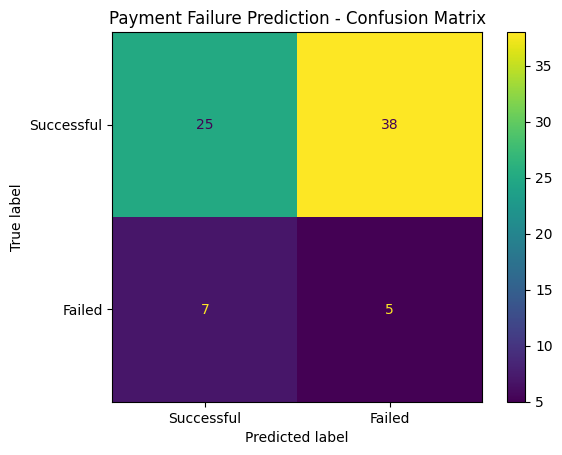

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Successful", "Failed"]
)

display.plot()
plt.title("Payment Failure Prediction - Confusion Matrix")
plt.show()

Failure Prediction

In [14]:
# Create a results table for the test transactions
results = pd.DataFrame({
    "transaction_id": df.iloc[split_index:]["transaction_id"].values,
    "actual_status": np.where(y_test.values == 1, "FAILED", "SUCCESS"),
    "failure_probability": y_prob
})

# Convert probability to percentage
results["failure_probability_pct"] = (
    results["failure_probability"] * 100
).round(2)

# Classify risk
results["risk_level"] = np.select(
    [
        results["failure_probability"] < 0.30,
        results["failure_probability"] < 0.70
    ],
    [
        "Low",
        "Medium"
    ],
    default="High"
)

# Sort highest-risk transactions first
results = results.sort_values(
    "failure_probability",
    ascending=False
).reset_index(drop=True)

print("Highest-risk transactions:")

from IPython.display import display as show_table

show_table(results.head(20))

Highest-risk transactions:


,transaction_id,actual_status,failure_probability,failure_probability_pct,risk_level
0,TXN_000831,FAILED,0.634515,63.45,Medium
1,TXN_000465,SUCCESS,0.632682,63.27,Medium
2,TXN_000482,FAILED,0.620927,62.09,Medium
3,TXN_000902,SUCCESS,0.620673,62.07,Medium
4,TXN_000473,SUCCESS,0.617427,61.74,Medium
5,TXN_000583,SUCCESS,0.606385,60.64,Medium
6,TXN_000607,FAILED,0.597632,59.76,Medium
7,TXN_000244,SUCCESS,0.594909,59.49,Medium
8,TXN_000716,SUCCESS,0.594031,59.40,Medium
9,TXN_000628,SUCCESS,0.593293,59.33,Medium


Visualize risk categories

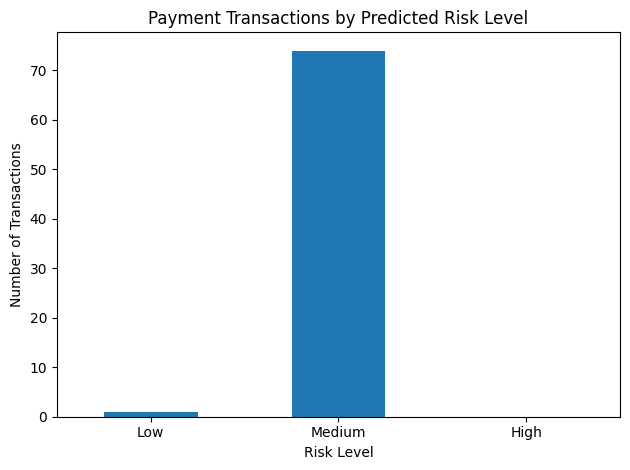

In [15]:
import matplotlib.pyplot as plt

risk_counts = results["risk_level"].value_counts().reindex(
    ["Low", "Medium", "High"],
    fill_value=0
)

risk_counts.plot(kind="bar")
plt.title("Payment Transactions by Predicted Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

prediction to csv export

In [16]:
results.to_csv(
    "payment_failure_predictions.csv",
    index=False
)

print("Prediction file saved successfully!")

from google.colab import files
files.download("payment_failure_predictions.csv")

Prediction file saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Optionally compare Random Forest

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, rf_pred, zero_division=0), 4))

if y_test.nunique() == 2:
    print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

Random Forest Results
Accuracy : 0.8133
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.4716
